# 03 — Model selection on the validation set

**Rules that make a comparison fair** (decided *before* looking at results):
1. Every model gets the **same** fit/validation split. The test set is not touched here.
2. **Primary metric: F1** (balances precision and recall, spec 8.3). **Also watched: false-positive rate** (alarm fatigue), training time, model size.
3. Record **every** run, not just the winner. Trying many settings and keeping the best inflates the result a little ("lucky winner"), so the final model is re-checked **once** on test.

In [1]:
import io, time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from cybershield.ml.preprocessing import TRAIN_CSV, load_csv, split_xy, build_preprocessor
from cybershield.ml.train import build_model, evaluate, SEED

X, y = split_xy(load_csv(TRAIN_CSV))
X_fit, X_val, y_fit, y_val = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
results = []

def run(name, pipeline, **settings):
    start = time.perf_counter()
    pipeline.fit(X_fit, y_fit)
    seconds = time.perf_counter() - start
    m = evaluate(y_val, pipeline.predict(X_val))
    buf = io.BytesIO(); joblib.dump(pipeline, buf)
    row = {"model": name, **settings, "f1": m["f1"], "precision": m["precision"], "recall": m["recall"],
           "fpr": m["false_positive_rate"], "train_s": seconds, "size_mb": buf.tell() / 1e6}
    results.append(row)
    return row

def table(rows):
    return pd.DataFrame(rows).round({"f1": 4, "precision": 4, "recall": 4, "fpr": 4, "train_s": 1, "size_mb": 1})

## 1. Three families of algorithms

| Algorithm | Idea | Needs scaled inputs? |
|---|---|---|
| **Logistic regression** | Draws one straight boundary: a weighted sum of features → probability. Simple, fast, explainable. | **Yes**: weights compare features, so bytes (millions) would drown flags (0/1). |
| **Random Forest** (bagging) | Many deep trees trained **independently** on random samples; they vote. | No: trees only ask "is x > threshold?" |
| **HistGradientBoosting** (boosting) | Trees built **one after another**, each fixing the previous ones' mistakes. Often the strongest on tables. | No |

For logistic regression we try two inputs: plain **scaling** (`StandardScaler`: mean 0, spread 1), and **log + scaling** (`log1p` squashes skewed values: 10 → 2.4, 10,000,000 → 16.1).

In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler, FunctionTransformer

def logreg(log=False):
    steps = [("preprocess", build_preprocessor())]
    if log:
        steps.append(("log", FunctionTransformer(np.log1p)))  # safe: we checked there are no negative values
    steps += [("scale", StandardScaler()), ("classifier", LogisticRegression(max_iter=2000))]
    return Pipeline(steps)

table([
    run("logreg", logreg(), inputs="scaled"),
    run("logreg", logreg(log=True), inputs="log+scaled"),
    run("random_forest", build_model(), inputs="default (100 trees)"),
    run("hist_gb", build_model(HistGradientBoostingClassifier(random_state=SEED)), inputs="default"),
])

,model,inputs,f1,precision,recall,fpr,train_s,size_mb
0,logreg,scaled,0.9550,0.9241,0.9881,0.1729,8.5,0.0
1,logreg,log+scaled,0.9569,0.9407,0.9736,0.1308,5.7,0.0
2,random_forest,default (100 trees),0.9707,0.9648,0.9767,0.0760,2.3,81.9
3,hist_gb,default,0.9680,0.9595,0.9766,0.0878,1.9,0.4


## 2. Random Forest: how many trees?
More trees = more voters. Accuracy usually rises, then **flattens**, while time and size keep growing linearly. We look for the elbow.

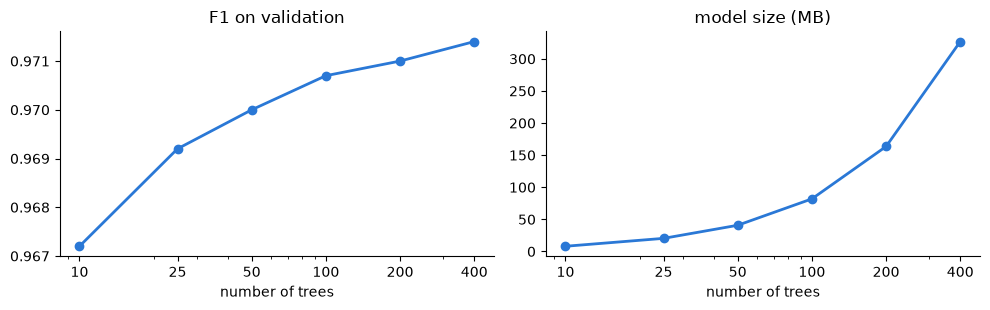

,n_estimators,f1,fpr,train_s,size_mb
0,10,0.9672,0.0700,0.6,8.1
1,25,0.9692,0.0811,0.9,20.4
2,50,0.9700,0.0765,1.3,40.8
3,100,0.9707,0.0760,2.4,81.9
4,200,0.9710,0.0766,4.1,163.5
5,400,0.9714,0.0760,7.8,326.9


In [3]:
trees = [10, 25, 50, 100, 200, 400]
curve = table([run("random_forest", build_model(RandomForestClassifier(n_estimators=n, random_state=SEED, n_jobs=-1)),
                   n_estimators=n) for n in trees])

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, col, label in [(axes[0], "f1", "F1 on validation"), (axes[1], "size_mb", "model size (MB)")]:
    ax.plot(curve.n_estimators, curve[col], marker="o", color="#2a78d6", linewidth=2)
    ax.set(xscale="log", xticks=trees, xticklabels=trees, xlabel="number of trees", title=label)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()
curve[["n_estimators", "f1", "fpr", "train_s", "size_mb"]]

## 3. Random Forest: other settings (a grid search)
- `max_depth`: how many questions deep a tree may go. `None` = until leaves are pure. Shallower = simpler, less **overfitting** (memorising training quirks).
- `min_samples_leaf`: a final answer must be backed by at least this many training rows. Higher = smoother rules, fewer one-off memorised cases.
- `class_weight="balanced"`: count each normal row more, since normals are the minority (32%). Pushes the model toward fewer false alarms.

A **grid search** tries every combination: 3 × 3 × 2 = 18 forests (50 trees each, enough per the curve above).

In [4]:
from sklearn.model_selection import ParameterGrid

grid = ParameterGrid({"max_depth": [None, 20, 10], "min_samples_leaf": [1, 5, 20], "class_weight": [None, "balanced"]})
rf_grid = table([run("random_forest", build_model(RandomForestClassifier(n_estimators=50, random_state=SEED, n_jobs=-1, **p)), **p)
                 for p in grid])
rf_grid.sort_values("f1", ascending=False)[["max_depth", "min_samples_leaf", "class_weight", "f1", "precision", "recall", "fpr", "size_mb"]]

,max_depth,min_samples_leaf,class_weight,f1,precision,recall,fpr,size_mb
3,20.0,1,NaN,0.9701,0.9619,0.9785,0.0827,20.8
0,NaN,1,NaN,0.9700,0.9645,0.9756,0.0765,40.8
1,NaN,5,NaN,0.9695,0.9593,0.9799,0.0886,16.0
4,20.0,5,NaN,0.9683,0.9574,0.9795,0.0929,11.2
9,NaN,1,balanced,0.9681,0.9743,0.9620,0.0541,43.3
5,20.0,20,NaN,0.9662,0.9520,0.9807,0.1053,5.0
2,NaN,20,NaN,0.9659,0.9530,0.9791,0.1029,5.6
10,NaN,5,balanced,0.9656,0.9768,0.9546,0.0483,17.3
12,20.0,1,balanced,0.9646,0.9780,0.9516,0.0456,22.8
13,20.0,5,balanced,0.9628,0.9776,0.9484,0.0463,12.4


## 4. HistGradientBoosting: a small grid
- `learning_rate`: how strongly each new tree corrects the previous ones. Smaller = more careful, needs more trees.
- `max_leaf_nodes`: how complex each tree may be.
- `max_iter`: number of boosting rounds (trees). Early stopping halts once validation-within-training stops improving.

In [5]:
hgb_grid = table([run("hist_gb", build_model(HistGradientBoostingClassifier(random_state=SEED, max_iter=300, **p)), **p)
                  for p in ParameterGrid({"learning_rate": [0.05, 0.1, 0.2], "max_leaf_nodes": [15, 31, 63]})])
hgb_grid.sort_values("f1", ascending=False)[["learning_rate", "max_leaf_nodes", "f1", "precision", "recall", "fpr", "train_s", "size_mb"]]

,learning_rate,max_leaf_nodes,f1,precision,recall,fpr,train_s,size_mb
5,0.10,63,0.9718,0.9664,0.9773,0.0724,4.4,2.2
2,0.05,63,0.9709,0.9640,0.9779,0.0779,4.6,2.2
4,0.10,31,0.9708,0.9637,0.9779,0.0785,3.6,1.1
8,0.20,63,0.9706,0.9652,0.9760,0.0751,2.7,1.3
7,0.20,31,0.9700,0.9642,0.9757,0.0771,2.5,0.7
6,0.20,15,0.9688,0.9630,0.9747,0.0799,2.7,0.5
1,0.05,31,0.9688,0.9616,0.9761,0.0831,3.7,1.1
3,0.10,15,0.9682,0.9613,0.9753,0.0837,3.1,0.6
0,0.05,15,0.9666,0.9583,0.9750,0.0904,3.3,0.6


## 5. Best of each family

In [6]:
all_runs = table(results)
best = all_runs.loc[all_runs.groupby("model").f1.idxmax()].sort_values("f1", ascending=False)
print(f"{len(all_runs)} runs in total")
best.dropna(axis=1, how="all")

37 runs in total


,model,inputs,f1,precision,recall,fpr,train_s,size_mb,n_estimators,learning_rate,max_leaf_nodes
33,hist_gb,NaN,0.9718,0.9664,0.9773,0.0724,4.4,2.2,NaN,0.1,63.0
9,random_forest,NaN,0.9714,0.9648,0.9780,0.0760,7.8,326.9,400.0,NaN,NaN
1,logreg,log+scaled,0.9569,0.9407,0.9736,0.1308,5.7,0.0,NaN,NaN,NaN
